In [6]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (VotingClassifier, BaggingClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, StackingClassifier)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, classification_report)

warnings.filterwarnings("ignore")

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
DATA_DIR = "/content/drive/MyDrive/image_mining/atelier2/DB2C"
print(os.path.exists(DATA_DIR))
print(os.listdir(DATA_DIR))

True
['obj_ship', 'obj_car', 'comparaison_modeles.csv']


In [9]:
IMG_SIZE = (60, 40)      # largeur x hauteur (moitié de 120x80)
GRAYSCALE = False        # on garde la couleur (voiture rouge, mer bleue...)
EXT = (".jpg", ".jpeg", ".png")

classes = sorted([d for d in os.listdir(DATA_DIR)
                  if os.path.isdir(os.path.join(DATA_DIR, d))])
print("Classes :", classes)

X_list, y_list = [], []
for c in classes:
    folder = os.path.join(DATA_DIR, c)
    for f in os.listdir(folder):
        if f.lower().endswith(EXT):
            img = Image.open(os.path.join(folder, f)).convert("RGB")
            if img.height > img.width:          # 5 images en portrait : on les tourne
                img = img.rotate(90, expand=True)
            img = img.resize(IMG_SIZE)
            X_list.append(np.asarray(img, dtype=np.float32).flatten() / 255.0)
            y_list.append(c)

X = np.array(X_list)
le = LabelEncoder()
y = le.fit_transform(y_list)
print("X :", X.shape, "| y :", y.shape)
print(pd.Series(y_list).value_counts())

Classes : ['obj_car', 'obj_ship']
X : (491, 7200) | y : (491,)
obj_car     401
obj_ship     90
Name: count, dtype: int64


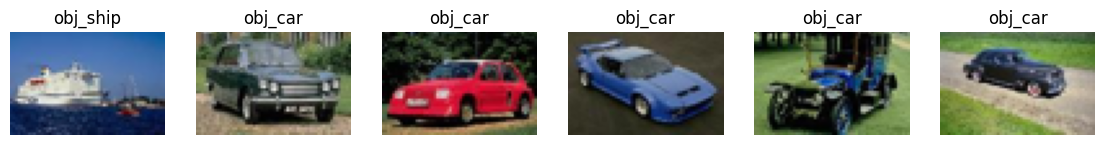

In [10]:
fig, axes = plt.subplots(1, 6, figsize=(14, 3))
for ax, i in zip(axes, np.random.choice(len(X), 6, replace=False)):
    ax.imshow(X[i].reshape(IMG_SIZE[1], IMG_SIZE[0], 3))
    ax.set_title(le.classes_[y[i]])
    ax.axis("off")
plt.show()

In [11]:
def make(model):
    return Pipeline([
        ("sc", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=42)),
        ("clf", model),
    ])

In [12]:
SEED = 42
TEST_SIZE = 0.2
N_ESTIMATORS = 30

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print(X_train.shape, X_test.shape)

(392, 7200) (99, 7200)


In [13]:
def base_models(proba=True):
    return {
        "SVM RBF":           SVC(kernel="rbf", probability=proba, class_weight="balanced", random_state=SEED),
        "SVM linéaire":      SVC(kernel="linear", probability=proba, class_weight="balanced", random_state=SEED),
        "SVM sigmoïde":      SVC(kernel="sigmoid", probability=proba, class_weight="balanced", random_state=SEED),
        "KNN (k=3)":         KNeighborsClassifier(n_neighbors=3),
        "KNN (k=5)":         KNeighborsClassifier(n_neighbors=5),
        "Arbre de décision": DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
    }

results = []
preds = {}

def evaluate(name, family, model):
    pipe = make(model)
    cv_acc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1).mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    preds[name] = pred
    results.append({
        "Famille": family,
        "Modèle": name,
        "CV acc": round(cv_acc, 4),
        "Accuracy": round(accuracy_score(y_test, pred), 4),
        "Balanced acc": round(balanced_accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, pred), 4),
    })
    print(f"[{family}] {name:30s} CV={cv_acc:.4f}  Test={results[-1]['Accuracy']:.4f}  F1={results[-1]['F1']:.4f}")
    return pipe, pred

In [14]:
cv_scores = {}
for n, m in base_models().items():
    evaluate(n, "Individuel", m)
    cv_scores[n] = results[-1]["CV acc"]

[Individuel] SVM RBF                        CV=0.9591  Test=0.9596  F1=0.8947
[Individuel] SVM linéaire                   CV=0.9616  Test=0.9697  F1=0.9189
[Individuel] SVM sigmoïde                   CV=0.9438  Test=0.9394  F1=0.8571
[Individuel] KNN (k=3)                      CV=0.9719  Test=0.9596  F1=0.8947
[Individuel] KNN (k=5)                      CV=0.9693  Test=0.9596  F1=0.8947
[Individuel] Arbre de décision              CV=0.9031  Test=0.8990  F1=0.7368


In [15]:
estimators = list(base_models().items())
weights = [cv_scores[n] for n, _ in estimators]

evaluate("Vote majoritaire", "Vote", VotingClassifier(estimators, voting="hard"))
evaluate("Vote moyenne (soft)", "Vote", VotingClassifier(estimators, voting="soft"))
evaluate("Vote pondéré", "Vote", VotingClassifier(estimators, voting="soft", weights=weights))

[Vote] Vote majoritaire               CV=0.9617  Test=0.9697  F1=0.9189
[Vote] Vote moyenne (soft)            CV=0.9668  Test=0.9596  F1=0.8947
[Vote] Vote pondéré                   CV=0.9693  Test=0.9596  F1=0.8947


(Pipeline(steps=[('sc', StandardScaler()),
                 ('pca', PCA(n_components=0.95, random_state=42)),
                 ('clf',
                  VotingClassifier(estimators=[('SVM RBF',
                                                SVC(class_weight='balanced',
                                                    probability=True,
                                                    random_state=42)),
                                               ('SVM linéaire',
                                                SVC(class_weight='balanced',
                                                    kernel='linear',
                                                    probability=True,
                                                    random_state=42)),
                                               ('SVM sigmoïde',
                                                SVC(class_weight='balanced',
                                                    kernel='sigmoid',
                          

In [16]:
for n, m in base_models(proba=False).items():
    evaluate(f"Bagging({n})", "Bagging",
             BaggingClassifier(estimator=m, n_estimators=N_ESTIMATORS,
                               bootstrap=True, random_state=SEED, n_jobs=-1))

[Bagging] Bagging(SVM RBF)               CV=0.9693  Test=0.9596  F1=0.8947
[Bagging] Bagging(SVM linéaire)          CV=0.9616  Test=0.9697  F1=0.9189
[Bagging] Bagging(SVM sigmoïde)          CV=0.9488  Test=0.9495  F1=0.8780
[Bagging] Bagging(KNN (k=3))             CV=0.9668  Test=0.9596  F1=0.8947
[Bagging] Bagging(KNN (k=5))             CV=0.9693  Test=0.9495  F1=0.8718
[Bagging] Bagging(Arbre de décision)     CV=0.9310  Test=0.9394  F1=0.8333


In [17]:
evaluate("AdaBoost(arbre p1)", "Boosting",
         AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                            n_estimators=N_ESTIMATORS, random_state=SEED))
evaluate("AdaBoost(arbre p3)", "Boosting",
         AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3),
                            n_estimators=N_ESTIMATORS, random_state=SEED))
evaluate("Gradient Boosting", "Boosting",
         GradientBoostingClassifier(n_estimators=90, random_state=SEED))

[Boosting] AdaBoost(arbre p1)             CV=0.9258  Test=0.9697  F1=0.9143
[Boosting] AdaBoost(arbre p3)             CV=0.9335  Test=0.9495  F1=0.8571
[Boosting] Gradient Boosting              CV=0.9360  Test=0.9495  F1=0.8571


(Pipeline(steps=[('sc', StandardScaler()),
                 ('pca', PCA(n_components=0.95, random_state=42)),
                 ('clf',
                  GradientBoostingClassifier(n_estimators=90, random_state=42))]),
 array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1,
        0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
        0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1]))

In [18]:
evaluate("Stacking (LogReg)", "Stacking",
         StackingClassifier(estimators=list(base_models().items()),
                            final_estimator=LogisticRegression(max_iter=1000),
                            cv=5, n_jobs=-1))

[Stacking] Stacking (LogReg)              CV=0.9693  Test=0.9697  F1=0.9189


(Pipeline(steps=[('sc', StandardScaler()),
                 ('pca', PCA(n_components=0.95, random_state=42)),
                 ('clf',
                  StackingClassifier(cv=5,
                                     estimators=[('SVM RBF',
                                                  SVC(class_weight='balanced',
                                                      probability=True,
                                                      random_state=42)),
                                                 ('SVM linéaire',
                                                  SVC(class_weight='balanced',
                                                      kernel='linear',
                                                      probability=True,
                                                      random_state=42)),
                                                 ('SVM sigmoïde',
                                                  SVC(class_weight='balanced',
                               

In [19]:
res = pd.DataFrame(results).sort_values(["F1", "Accuracy"], ascending=False).reset_index(drop=True)
res.to_csv("resultats_ensemble_db2c.csv", index=False, encoding="utf-8-sig")
res

,Famille,Modèle,CV acc,Accuracy,Balanced acc,Precision,Recall,F1
0,Individuel,SVM linéaire,0.9616,0.9697,0.9599,0.8947,0.9444,0.9189
1,Vote,Vote majoritaire,0.9617,0.9697,0.9599,0.8947,0.9444,0.9189
2,Bagging,Bagging(SVM linéaire),0.9616,0.9697,0.9599,0.8947,0.9444,0.9189
3,Stacking,Stacking (LogReg),0.9693,0.9697,0.9599,0.8947,0.9444,0.9189
4,Boosting,AdaBoost(arbre p1),0.9258,0.9697,0.9383,0.9412,0.8889,0.9143
5,Individuel,SVM RBF,0.9591,0.9596,0.9537,0.8500,0.9444,0.8947
6,Individuel,KNN (k=3),0.9719,0.9596,0.9537,0.8500,0.9444,0.8947
7,Individuel,KNN (k=5),0.9693,0.9596,0.9537,0.8500,0.9444,0.8947
8,Vote,Vote moyenne (soft),0.9668,0.9596,0.9537,0.8500,0.9444,0.8947
9,Vote,Vote pondéré,0.9693,0.9596,0.9537,0.8500,0.9444,0.8947


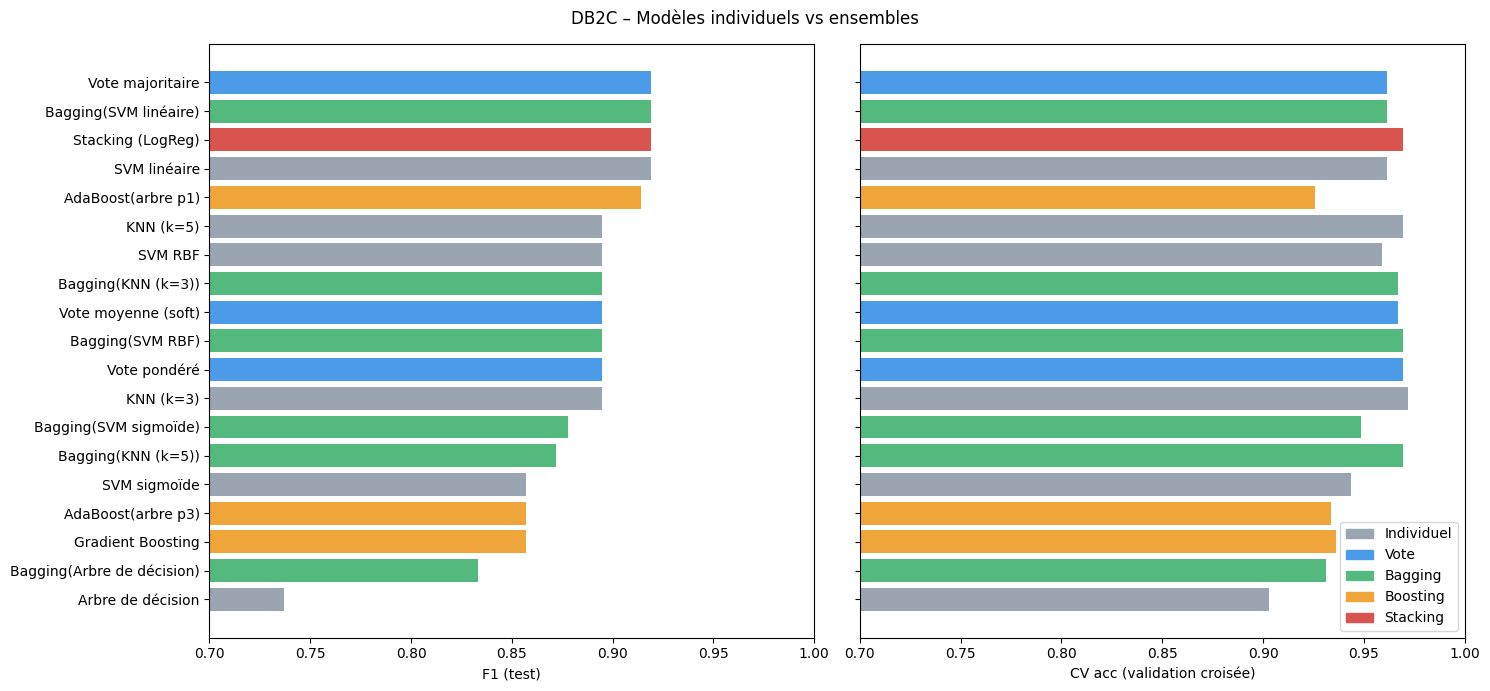

In [20]:
colors = {"Individuel": "#9aa5b1", "Vote": "#4c9be8", "Bagging": "#53b97c",
          "Boosting": "#f0a53a", "Stacking": "#d9534f"}
r = res.sort_values("F1")
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for ax, col in zip(axes, ["F1", "CV acc"]):
    ax.barh(r["Modèle"], r[col], color=[colors[f] for f in r["Famille"]])
    ax.set_xlabel(col + (" (test)" if col == "F1" else " (validation croisée)"))
    ax.set_xlim(0.7, 1.0)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[1].legend(handles, colors.keys(), loc="lower right")
plt.suptitle("DB2C – Modèles individuels vs ensembles")
plt.tight_layout()
plt.savefig("comparaison_ensemble_db2c.png", dpi=150)
plt.show()

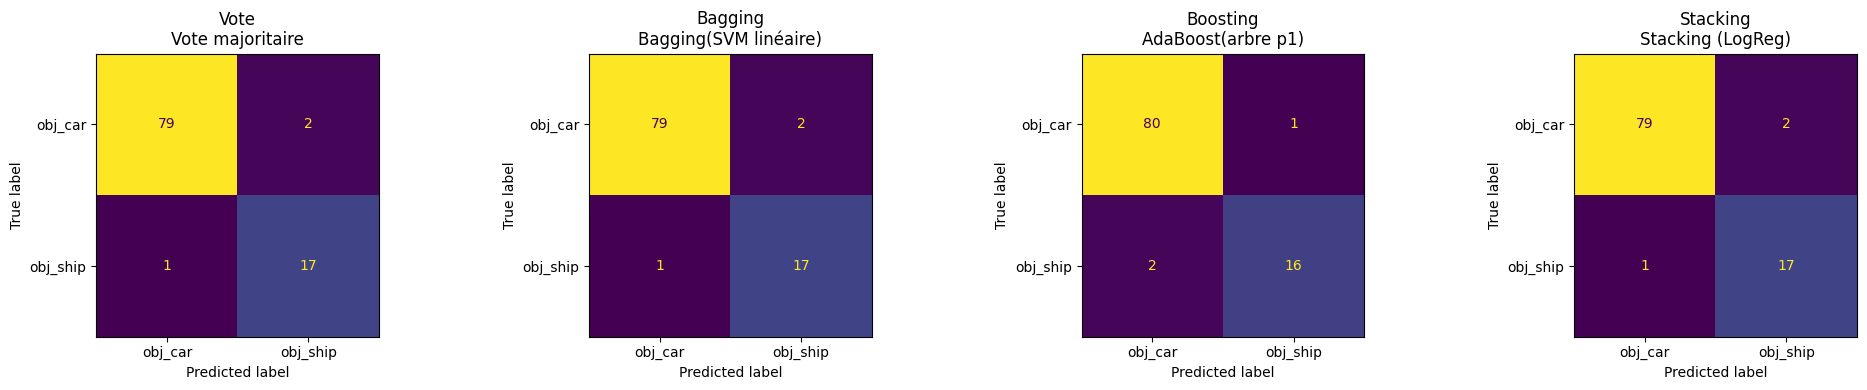

In [25]:
from sklearn.metrics import ConfusionMatrixDisplay

familles = ["Vote", "Bagging", "Boosting", "Stacking"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, f in zip(axes, familles):
    nom = res[res["Famille"] == f].iloc[0]["Modèle"]   # meilleure variante de la famille
    ConfusionMatrixDisplay.from_predictions(y_test, preds[nom], display_labels=le.classes_,
                                            ax=ax, colorbar=False)
    ax.set_title(f"{f}\n{nom}")
plt.tight_layout()
plt.show()

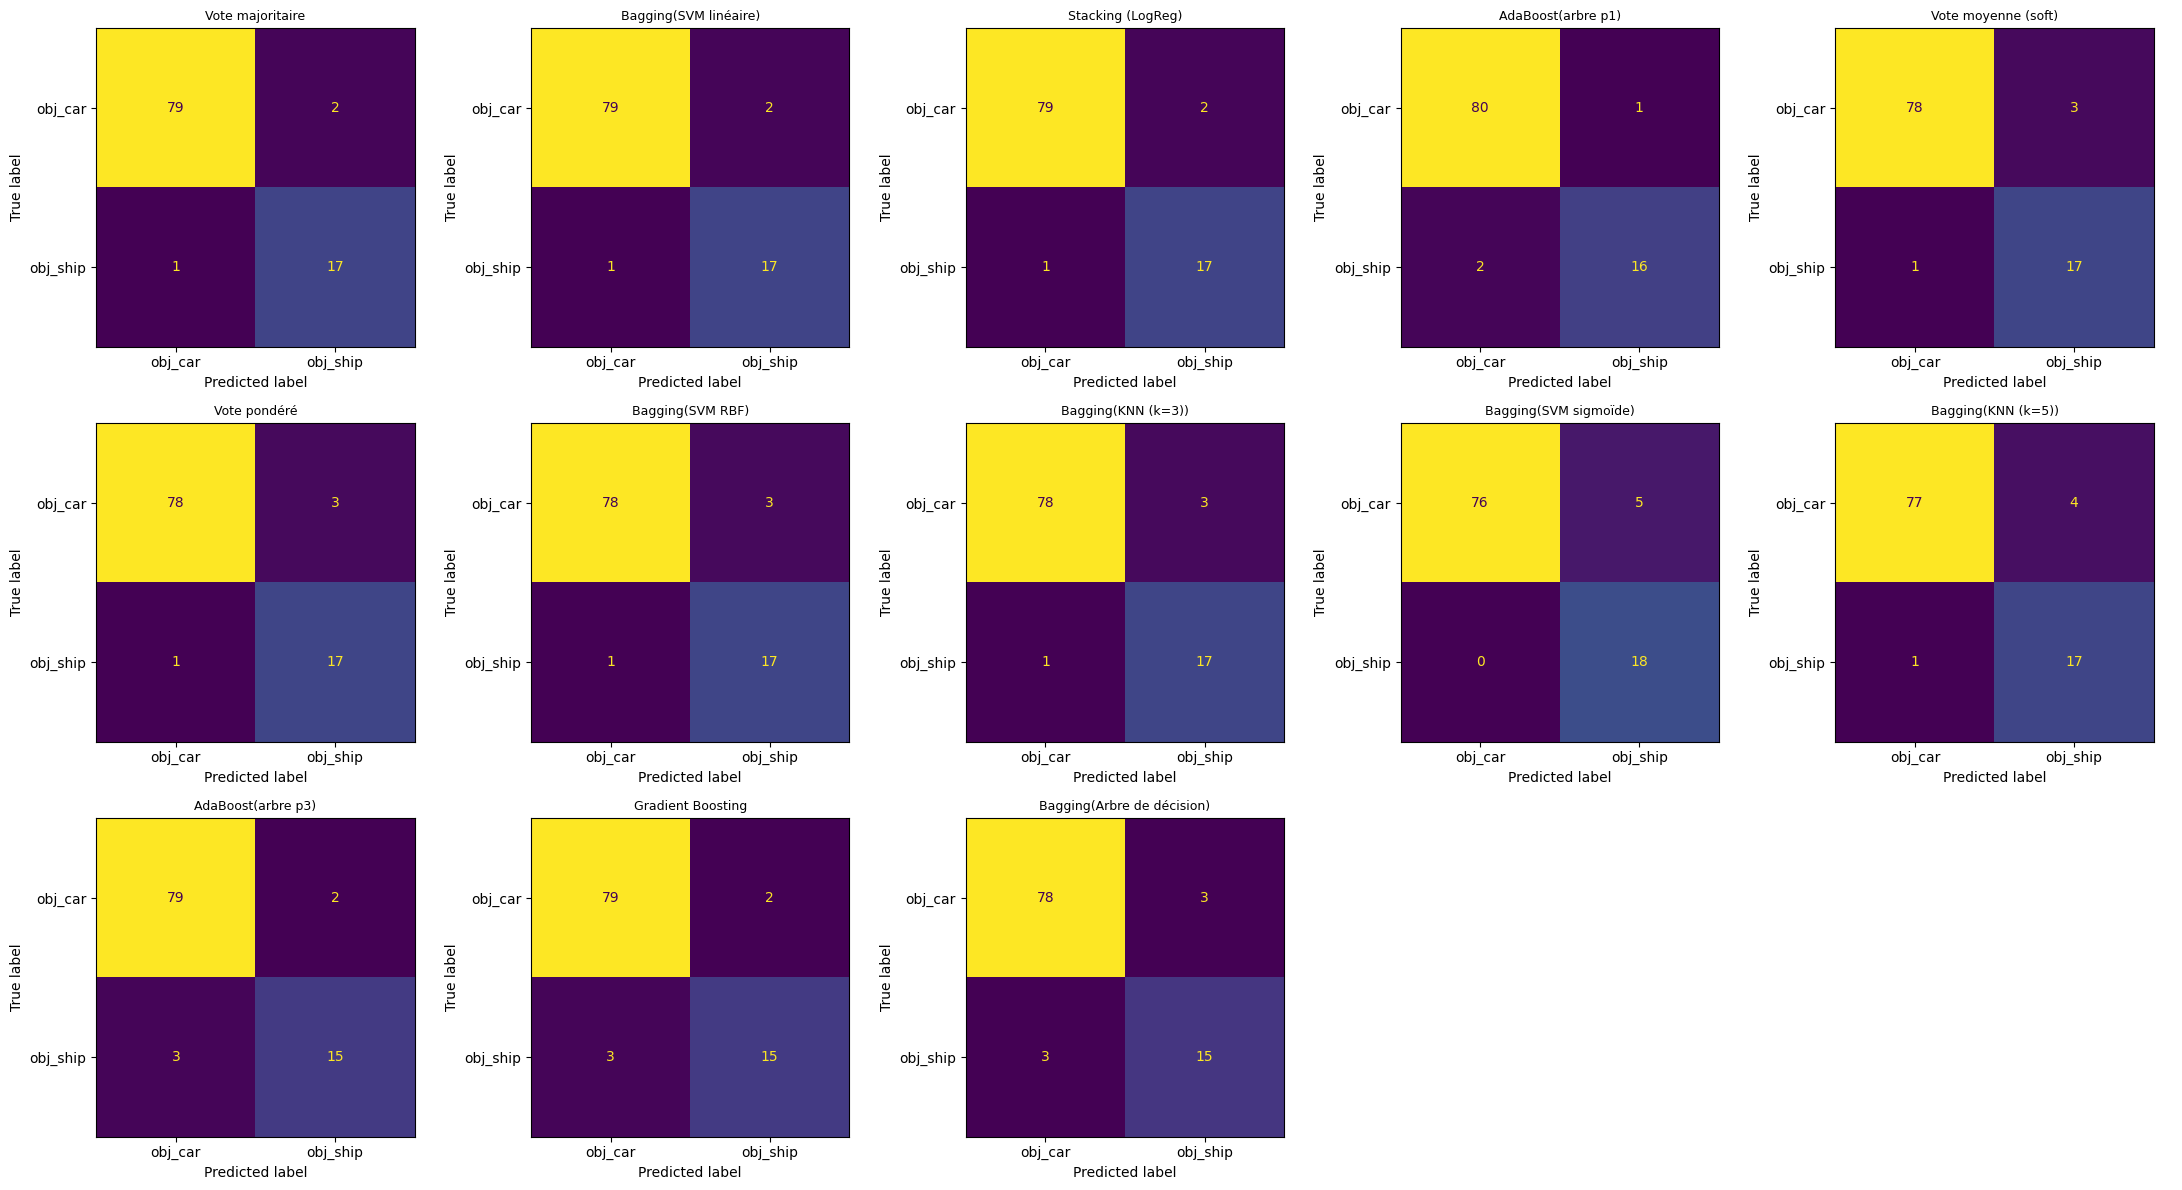

In [27]:
ens = res[res["Famille"] != "Individuel"]["Modèle"].tolist()   # 13 modèles
fig, axes = plt.subplots(3, 5, figsize=(22, 12))
for ax, nom in zip(axes.ravel(), ens):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[nom], display_labels=le.classes_,
                                            ax=ax, colorbar=False)
    ax.set_title(nom, fontsize=9)
for ax in axes.ravel()[len(ens):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [24]:
par_methode = (res.groupby("Famille")
                  .agg(Nb_modèles=("Modèle", "count"),
                       CV_moyenne=("CV acc", "mean"),
                       F1_moyen=("F1", "mean"),
                       F1_max=("F1", "max"),
                       Recall_moyen=("Recall", "mean"))
                  .round(4)
                  .sort_values("F1_moyen", ascending=False))
par_methode

,Nb_modèles,CV_moyenne,F1_moyen,F1_max,Recall_moyen
Famille,,,,,
Stacking,1,0.9693,0.9189,0.9189,0.9444
Vote,3,0.9659,0.9028,0.9189,0.9444
Bagging,6,0.9578,0.8819,0.9189,0.9352
Boosting,3,0.9318,0.8762,0.9143,0.8518
Individuel,6,0.9515,0.8662,0.9189,0.9259
